
# Levinthal (1997): Adaptation on Rugged Landscapes

This notebook reproduces the results of

> Levinthal, D. A. (1997). Adaptation on rugged landscapes. *Management Science*, 43(7), 934-950.
> https://doi.org/10.1287/mnsc.43.7.934

with `nkscape`, in the order of the article. The values used for comparison are taken directly from
the article or read off the figures Levinthal published.

| Section of the article | Result |
|---|---|
| 3.1 | Figure 1: forms over time, local search |
| 3.1 | Figure 2: distribution of forms on one landscape |
| 3.2 | Figure 3: radiation of forms with long jumps |
| 3.3 | Figure 4: forms over time, selection only |
| 3.4 | Figure 5: adaptation and selection on one landscape |
| 4 | Figure 6: survival after one attribute's contribution changes |
| 4.1 | Figure 7: long jumps of survivors and non-survivors |
| 5 | Figure 8: number of local peaks |
| 5.1 | Standard deviation of fitness; Figure 9: survival with noisy search |


In [1]:
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import nkscape as nk

# fmt: off
N = 10            # attributes per form
POPULATION = 100  # organizations per landscape
T = 50            # periods per run
RUNS = 100        # landscapes and populations per setting; averaged results are means over them
SEED = 1997       # master seed; every run derives its own random stream from it
# fmt: on

ARTICLE = {"marker": "o", "color": "tab:red", "markersize": 4, "linestyle": "none"}
FIGURES = Path(
    "figures"
)  # every figure is also saved here, so the notebook can be read without running it
FIGURES.mkdir(exist_ok=True)


def show(name):
    plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


## 2. The model

### Construction of the NK landscape

We follow the notation of Wall (2016, p. 159; 2023, p. 278). An organization's form is a vector of
$N$ binary attributes,

$$\mathbf{d} = (d_1, \dots, d_N), \qquad d_i \in \{0, 1\}, \tag{1}$$

so that there are $2^N$ forms, i.e., $2^{10} = 1{,}024$ for Levinthal's $N = 10$ (pp. 936, 939).
The contribution of attribute $i$ depends on its own value and on the values of the $K$ attributes
that follow it in the vector, which is treated as circular (p. 937, fn. 4):

$$C_i = c_i\left(d_i;\, d_{i+1}, \dots, d_{i+K}\right), \qquad \text{indices wrapping around after } N. \tag{2}$$

Each $c_i$ is a contribution table with $2^{K+1}$ entries. The entries are drawn from a uniform
distribution on $[0, 1]$ and stay fixed until the environment changes. The fitness $V(\mathbf{d})$
of a form $\mathbf{d}$ is the average contribution of its $N$ attributes (pp. 937, 939):

$$V(\mathbf{d}) = \frac{1}{N} \sum_{i=1}^{N} C_i . \tag{3}$$

The neighborhood of a form consists of the $N$ forms that differ from it in exactly one attribute
(p. 937), i.e., that lie at a Hamming distance of 1. A local peak is a form that has no neighbor
with higher fitness.

*In `nkscape`:* `nk.Landscape.next_k(N, K, rng)` builds such a landscape; `fitness(d)`,
`neighbour_fitness(d)` and `peaks()` give $V$, the fitness of the $N$ neighbors and the local
peaks.

### The environment

The environment in Levinthal's model is an NK landscape as described above. All organizations of
one specific run share the same landscape, which stays fixed once drawn. Each organization is
represented by a vector $\mathbf{d}$ with $N = 10$ dimensions, one for each of its attributes
(pp. 938-939). Because the environment is the same for all organizations within one simulation
run, the differences among them that persist over time must result from their search process and
not from the environment.

The interdependence among attributes, which is central to the research question, is reflected in
the model only through the integer $K$. When one attribute changes, the fitness contributions of
$K$ other attributes change with it (p. 937). $K$ therefore sets how many attributes are connected;
however, it does not determine in what way. Because contributions are random draws, the model is
agnostic about how attributes interact and about what they stand for (p. 936).

In contrast to the other experiments, in which the landscape stays fixed, Levinthal also runs
experiments in which the environment changes. Halfway through the run, at period 25, he redraws
the contribution table of one attribute, or of five (pp. 944, 946). Redrawing one table changes the
fitness of any form by at most $1/N = 0.1$ and the expected immediate impact does not depend on $K$
(p. 944). Differences in survival across $K$ therefore reflect differences in the ability to adapt,
not in the size of the shock.

### Agents and their behavioral assumptions

**Bounded rationality.** The research questions rest on the assumption that organizations cannot
simply pick the best form. A fully rational organization would evaluate all 1,024 forms and move
to the global maximum at once (see Wall 2023, p. 273). All organizations on a landscape would then
adopt the same form, and neither lasting diversity nor an effect of founding conditions could
arise. The model therefore requires an implementation of bounded rationality (Simon 1955). This
means that organizations have limited information as well as a limited capacity to process it, so
they look for improvements close to what they already do instead of calculating the best solution.
Levinthal builds his organizations' search on this idea, drawing on March and Simon (1958) and
Cyert and March (1963), and interprets it as local hill climbing (pp. 935, 937). Within its
neighborhood, an organization easily finds which of its $N$ neighbors are fitter and can switch to
one of them by flipping a single attribute (p. 937). Beyond its neighborhood, an organization sees
only one other randomly drawn form per period. Moving to such a distant form is what Levinthal,
following Kauffman (1993), calls a long jump (p. 938). The effect of $K$ would diminish if
organizations could look farther, but it would persist as long as they cannot see the entire
landscape (pp. 940-941).

**Local search.** The search has two components. The first is local search, in which an
organization examines the $N$ neighbors of its current form. It does not look for the fittest
neighbor but adopts "merely the first superior form that it discovers" (p. 938). Stopping at the
first acceptable alternative instead of searching for the best one corresponds to a satisficing
search algorithm (Simon 1955; Wall 2023, p. 270). Satisficing search differs from the usual
description of hill climbing, in which an organization moves to its best neighbor (e.g., Csaszar
2018, p. 4). The difference matters, because Appendix A of the paper shows that it can change which
peak an organization reaches.

*In `nkscape`:* `nk.agents.HillClimber("first")`. The article does not say in which order the
neighbors are examined; Levinthal's original Turbo Pascal program (`nlandf.pas`,
http://www.cs.unibo.it/~fioretti/CODE/NK/) tries $d_1, d_2, \dots$ in fixed order, and so does
`"first"`. Steepest ascent is `HillClimber("best")`.

**Long jumps.** The second component is the long jump. In every period, each organization draws
one of the $2^N$ forms at random and switches to it if it has a higher fitness level. Levinthal
interprets such a move, following Tushman and Romanelli (1985), as a reorientation (p. 938). Local
search and long jumps correspond to exploitation and exploration (March 1991; see Wall 2016,
p. 145). In the simulation, every organization does both in every period, searching locally and
also considering one possible long jump. The model contains no rule that makes poorly performing
organizations change radically. Nevertheless, they do so more often, which results from the rule
that only fitter forms are adopted (p. 938). The lower the fitness of the current form, the more
likely it is that the randomly drawn form of a long jump is better. Levinthal also notes that his
rules favor change, because moving costs nothing and never lowers fitness (p. 938). The
difficulties of tightly coupled organizations shown in section 4 thus arise despite these
favorable assumptions.

*In `nkscape`:* `HillClimber("first", long_jumps=True)`. As in the program, the jump is tried right
after the local move and compared with the form held then.

### Population

In every period, selection decides which organization survives. Levinthal takes the rule from
biology: the closer the level of an organization's fitness is to that of the fittest organization
in the population, the more likely it is to survive (p. 938). The article gives no formula for
this, so we follow the original program. The probability that organization $j$ survives period $t$
is its fitness divided by the highest fitness in the population,

$$p_{j,t} = \frac{V(\mathbf{d}_{j,t-1})}{\max_k V(\mathbf{d}_{k,t-1})}. \tag{4}$$

The fittest organization therefore always survives, and an organization with half its fitness
survives with a probability of one half. The population is held at 100, so each organization that
fails is replaced by a new one (pp. 938-939). A new organization either receives a random form or
copies the form of a survivor. Which of the two happens depends on the genetic load, a measure
from population genetics of how far the average fitness lies below the highest (p. 939),

$$L_t = 1 - \frac{\bar V_{t-1}}{V_{t-1}^{\max}}, \tag{5}$$

where $\bar V_{t-1}$ is the average and $V_{t-1}^{\max}$ the highest fitness at the end of the
previous period. With probability $L_t$, the new organization receives a random form. Otherwise,
it copies a survivor where fitter survivors are more likely to be copied (pp. 939-940). The idea
behind this rule is that founders imitate existing organizations mainly when the population as a
whole is doing well (p. 939). Eq. 5 is the program's rule; the article speaks of the genetic load
of the surviving set (p. 940).

**Sequence and parameters.** Within each period, the model first decides which organizations
survive, then lets the survivors search before new organizations enter (pp. 939-940).

*In `nkscape`:* the `Selection` population rule in the next cell. `nk.run` lets every agent search
first and then applies the rule, which decides survival from the fitness of period $t-1$ and
discards the search of a non-survivor; the histories are the same as with the program's order,
because every organization draws from its own random stream.

| Parameter | Meaning | Values |
|---|---|---|
| $N$ | Attributes per form | 10 ($2^{10} = 1{,}024$ forms) |
| $K$ | Interacting attributes per attribute | 0, 1, 5 |
| Population | Organizations per landscape | 100 |
| $T$ | Periods per run | 50 |
| Runs | Landscapes and populations per setting | 100 / one landscape in Fig. 2 and Fig. 5 |
| Initial forms | Starting positions | Random / one common form (Fig. 3) |
| Mechanisms | Processes switched on | Fig. 1: local search; Fig. 3: local search, long jumps; Fig. 4: selection, founding; Figs. 5-7, 9: all four |
| Landscape change | Tables redrawn at $t = 25$ | 1 attribute (Figs. 6, 9); 5 attributes (Fig. 7) |
| $\varepsilon$ | Noise level of evaluation | 0, 0.025 (Fig. 9) |


In [2]:
class Selection(nk.PopulationRule):
    """Eq. 4 and 5: survival relative to the leader; entrants random or copied from a survivor."""

    def __init__(self, make_agent, first_load=None):
        self.make_agent = make_agent
        self.first_load = first_load

    def decide(self, population, proposals, landscape, rng):
        living = np.flatnonzero(population.alive)
        v = population.fitness[living]
        v_max = v.max()
        load = 1 - v.mean() / v_max
        if population.period == 1 and self.first_load is not None:
            load = self.first_load

        survives = rng.random(living.size) < v / v_max
        survivors = living[survives]
        forms = np.array([ranked[0] for ranked in proposals])
        v_survivors = landscape.fitness_cube()[tuple(forms[survivors].T)]

        entrants = []
        for _ in range(living.size - survivors.size):
            if rng.random() < load:
                form = landscape.random_configuration(rng)
            else:
                form = forms[rng.choice(survivors, p=v_survivors / v_survivors.sum())]
            entrants.append((self.make_agent(), form))
        return nk.PopulationDecision(forms, dies=living[~survives], born=entrants)


### Counting distinct forms

Levinthal's measure of order is the number of distinct forms in the population. `distinct_forms`
reads each organization's form as a binary number (010 → 2, 101 → 5, …), so equal forms give equal
numbers, and counts the distinct numbers among the living organizations, period by period.


In [3]:
def form_codes(configs):
    return configs.astype(int) @ (1 << np.arange(N))


def distinct_forms(result):
    codes = form_codes(result.configs)
    return np.array([len(np.unique(codes[result.alive[:, t], t])) for t in range(codes.shape[1])])


def simulate(k, make_agent, same_start=False, selection=False):
    results = []
    for stream in np.random.default_rng([SEED, k]).spawn(RUNS):
        landscape_rng, start_rng, run_rng = stream.spawn(3)
        landscape = nk.Landscape.next_k(N, k, rng=landscape_rng)
        starts = [landscape.random_configuration(start_rng)] * POPULATION if same_start else None
        agents = [make_agent() for _ in range(POPULATION)]
        rules = [Selection(make_agent)] if selection else []
        result = nk.run(landscape, agents, T, run_rng, starts=starts, rules=rules)
        assert (result.alive.sum(axis=0) == POPULATION).all()
        results.append(result)
    return results


def forms_over_time(results):
    return np.array([distinct_forms(result) for result in results])


def plot_forms(forms, article, styles, title, ylim, name):
    _, ax = plt.subplots(figsize=(6.5, 3.8))
    for k, counts in forms.items():
        ax.plot(counts.mean(axis=0), color="black", linestyle=styles[k], label=f"nkscape, K = {k}")
    for points in article.values():
        ax.plot(list(points), list(points.values()), **ARTICLE)
    ax.plot([], [], label="article (read off the figure)", **ARTICLE)
    ax.set(xlabel="Time", ylabel="Distinct forms", xlim=(0, 48), ylim=ylim, title=title)
    ax.legend(frameon=False, fontsize=8)
    show(name)
    for k, points in article.items():
        periods = sorted(points)
        print(f"K = {k}   period ", "".join(f"{t:6d}" for t in periods))
        print("        nkscape", "".join(f"{forms[k].mean(axis=0)[t]:6.1f}" for t in periods))
        print("        article", "".join(f"{points[t]:6.1f}" for t in periods))


## 3.1 Figure 1: emergence of order under local adaptation

Levinthal places 100 organizations at random forms on each of 100 landscapes and lets them search
locally for 50 periods, without long jumps and without selection (p. 940). The measure is the
number of distinct forms in the population, averaged over the landscapes, for $K = 0$, 1 and 5.
With $K = 0$ the landscape has a single peak, which every organization reaches within at most $N$
periods, so the population ends with one form. With $K > 0$ the organizations that start in the
same basin of attraction converge on the same peak, and the number of forms that remains is the
number of peaks reached (pp. 940-941).


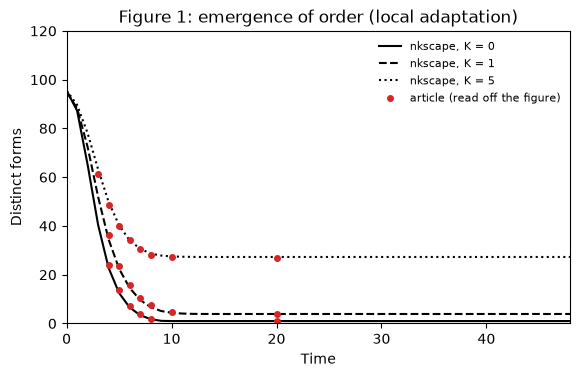

K = 0   period       4     5     6     7     8    20
        nkscape   22.8  12.5   6.6   3.4   1.8   1.0
        article   24.0  13.7   7.2   3.7   2.0   1.0
K = 1   period       4     5     6     7     8    10    20
        nkscape   34.5  22.5  14.6   9.7   6.7   4.4   3.9
        article   36.2  23.5  15.6  10.6   7.4   4.9   3.9
K = 5   period       3     4     5     6     7     8    10    20
        nkscape   63.2  49.9  40.3  34.1  30.7  28.7  27.5  27.3
        article   61.5  48.8  40.1  34.2  30.6  28.2  27.3  26.8


In [4]:
local = {k: simulate(k, lambda: nk.agents.HillClimber("first")) for k in (0, 1, 5)}
local_forms = {k: forms_over_time(results) for k, results in local.items()}

article_fig1 = {
    0: {4: 24.0, 5: 13.7, 6: 7.2, 7: 3.7, 8: 2.0, 20: 1.0},
    1: {4: 36.2, 5: 23.5, 6: 15.6, 7: 10.6, 8: 7.4, 10: 4.9, 20: 3.9},
    5: {3: 61.5, 4: 48.8, 5: 40.1, 6: 34.2, 7: 30.6, 8: 28.2, 10: 27.3, 20: 26.8},
}  # fmt: skip
plot_forms(
    local_forms,
    article_fig1,
    {0: "-", 1: "--", 5: ":"},
    "Figure 1: emergence of order (local adaptation)",
    (0, 120),
    "fig1",
)

assert (local_forms[0][:, -1] == 1).all()
assert local_forms[0][:, -1].mean() < local_forms[1][:, -1].mean() < local_forms[5][:, -1].mean()


The article prints one set of numbers for this figure, the average number of distinct forms at the
start: 95.44, 95.57 and 95.61 for $K = 0$, 1 and 5 (p. 940). This value does not depend on the
model: drawing 100 forms at random out of 1,024 gives on average
$1024\,[1 - (1 - 1/1024)^{100}] = 95.32$ distinct ones.



## 3.1 Figure 2: distribution of forms on one landscape

Figure 2 shows a single arbitrary landscape with $K = 1$ after local search: the organizations sit
on four peaks, and the higher peaks hold more of them, because the basin of attraction of a peak
tends to be broader the higher the peak is (p. 941). The landscape below is another random draw
with six peaks, all of them reached; because the two landscapes differ, only the kind of pattern
can be compared, not the number of peaks or how many organizations sit on each.


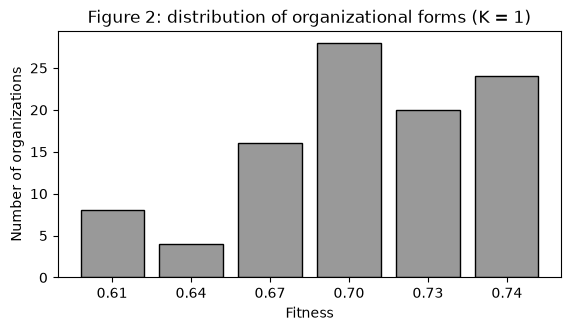

6 peaks on this landscape, 6 of them reached


In [5]:
stream = np.random.default_rng([SEED, 1]).spawn(RUNS)[0]
landscape_rng, _, run_rng = stream.spawn(3)
one_landscape = nk.Landscape.next_k(N, 1, rng=landscape_rng)
agents = [nk.agents.HillClimber("first") for _ in range(POPULATION)]
result = nk.run(one_landscape, agents, T, run_rng)

fitness, counts = np.unique(result.fitness[:, -1], return_counts=True)
_, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar([f"{f:.2f}" for f in fitness], counts, color="0.6", edgecolor="black")
ax.set(
    xlabel="Fitness",
    ylabel="Number of organizations",
    title="Figure 2: distribution of organizational forms (K = 1)",
)
show("fig2")

print(f"{one_landscape.count_peaks()} peaks on this landscape, {len(fitness)} of them reached")
assert all(one_landscape.is_peak(config) for config in result.configs[:, -1])


## 3.2 Figure 3: radiation of forms

Now all 100 organizations on a landscape begin with the same, arbitrarily chosen form and, besides
local search, may long-jump; selection stays off (p. 942). In the first periods many long jumps
succeed and the number of forms explodes; local search then gathers the organizations on a small
set of peaks, so that the count falls again and settles near the number of peaks that stay
occupied.


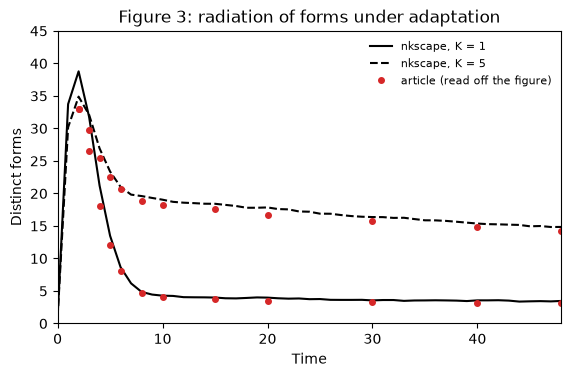

K = 1   period       2     3     4     5     6     8    10    15    20    30    40    48
        nkscape   38.8  31.8  21.2  13.5   8.7   4.9   4.3   4.0   4.0   3.5   3.6   3.5
        article   33.0  26.6  18.1  12.0   8.0   4.7   4.0   3.7   3.5   3.3   3.1   3.1
K = 5   period       2     3     4     5     6     8    10    15    20    30    40    48
        nkscape   34.9  32.1  26.9  23.4  21.0  19.6  19.0  18.4  17.9  16.4  15.4  14.8
        article   33.0  29.8  25.5  22.5  20.7  18.8  18.2  17.6  16.7  15.7  14.8  14.2


In [6]:
radiation = {
    k: forms_over_time(
        simulate(k, lambda: nk.agents.HillClimber("first", long_jumps=True), same_start=True)
    )
    for k in (1, 5)
}

article_fig3 = {
    1: {2: 33.0, 3: 26.6, 4: 18.1, 5: 12.0, 6: 8.0, 8: 4.7, 10: 4.0, 15: 3.7, 20: 3.5, 30: 3.3, 40: 3.1, 48: 3.1},
    5: {2: 33.0, 3: 29.8, 4: 25.5, 5: 22.5, 6: 20.7, 8: 18.8, 10: 18.2, 15: 17.6, 20: 16.7, 30: 15.7, 40: 14.8, 48: 14.2},
}  # fmt: skip
plot_forms(
    radiation,
    article_fig3,
    {1: "-", 5: "--"},
    "Figure 3: radiation of forms under adaptation",
    (0, 45),
    "fig3",
)


The curves agree from about period 5 on. The height of the early peak depends on how good the
common starting form of each landscape happens to be, so it varies between landscapes; even an
average over 100 landscapes moves by several forms from one master seed to the next, and
Levinthal's figure is one such average.


In [7]:
for k, forms in radiation.items():
    peak = forms.mean(axis=0).argmax()
    height = forms.mean(axis=0)[peak]
    error = forms[:, peak].std(ddof=1) / np.sqrt(RUNS)
    print(f"K = {k}: peak of {height:.1f} forms in period {peak}, standard error {error:.1f}")
    assert (forms[:, 0] == 1).all()
    assert peak <= 3

K = 1: peak of 38.8 forms in period 2, standard error 2.8
K = 5: peak of 34.9 forms in period 2, standard error 2.6



## 3.3 Figure 4: emergence of order under selection

Here organizations never change their form; all change comes from births and deaths
(pp. 942-943): each period an organization survives with probability Eq. 4, and each failed one
is replaced by an entrant that receives a random form with probability Eq. 5 and otherwise copies
a survivor. Selection reduces the number of forms much more slowly than local search and almost
independently of $K$, since survival compares every organization with the leader and ignores where
the peaks lie.


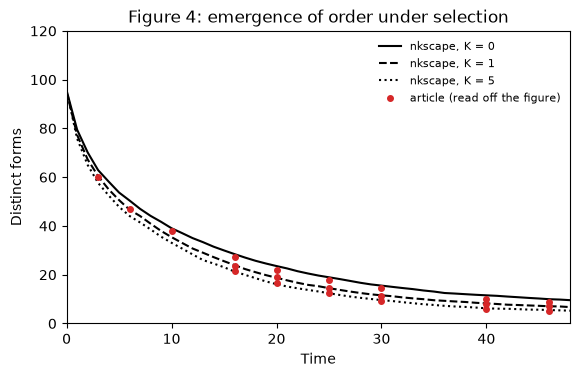

K = 0   period       3     6    10    16    20    25    30    40    46
        nkscape   62.9  50.4  39.1  28.5  23.6  18.9  15.5  11.6  10.0
        article   60.1  47.1  37.8  27.2  22.0  17.8  14.4  10.2   8.9
K = 1   period      16    20    25    30    40    46
        nkscape   23.9  18.8  14.5  11.6   8.2   7.1
        article   23.4  18.9  14.6  11.3   8.0   7.3
K = 5   period      16    20    25    30    40    46
        nkscape   21.3  16.1  12.4   9.6   6.2   5.5
        article   21.6  16.6  12.5   9.4   6.0   5.1


In [8]:
class Stay(nk.Agent):
    def step(self, config, landscape, rng, population):
        return config


selection_only = {k: forms_over_time(simulate(k, Stay, selection=True)) for k in (0, 1, 5)}

article_fig4 = {
    0: {3: 60.1, 6: 47.1, 10: 37.8, 16: 27.2, 20: 22.0, 25: 17.8, 30: 14.4, 40: 10.2, 46: 8.9},
    1: {16: 23.4, 20: 18.9, 25: 14.6, 30: 11.3, 40: 8.0, 46: 7.3},
    5: {16: 21.6, 20: 16.6, 25: 12.5, 30: 9.4, 40: 6.0, 46: 5.1},
}  # fmt: skip
plot_forms(
    selection_only,
    article_fig4,
    {0: "-", 1: "--", 5: ":"},
    "Figure 4: emergence of order under selection",
    (0, 120),
    "fig4",
)

final = {k: forms[:, -1].mean() for k, forms in selection_only.items()}
assert final[0] > final[1] > final[5]
assert all(selection_only[k].mean(axis=0)[10] > local_forms[k].mean(axis=0)[10] for k in (0, 1, 5))


## 3.4 Figure 5: adaptation and selection together, on one landscape

With all mechanisms active, local search and selection act in sequence (pp. 943-944). Within a few
periods local search decides which forms remain in play; afterwards selection changes how many
organizations hold each of them, toward the fittest of the forms discovered, which need not be the
fittest form on the landscape. Figure 5 shows this for one arbitrary landscape with $K = 1$: four
forms at periods 10, 30 and 50. Below is the same picture for another arbitrary landscape with
$K = 1$, the four most common forms of period 10; on this landscape the form that prevails is also
its global maximum.


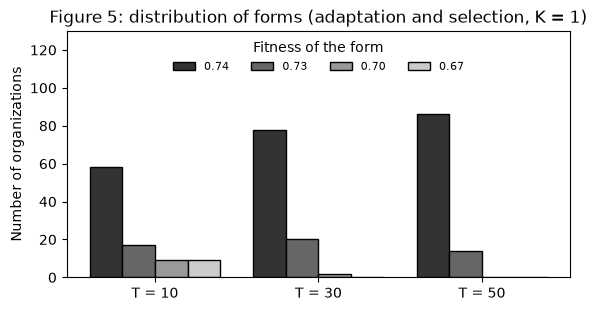

highest fitness on this landscape: 0.74


In [9]:
def climber():
    return nk.agents.HillClimber("first", long_jumps=True)


result = nk.run(
    one_landscape, [climber() for _ in range(POPULATION)], T, run_rng, rules=[Selection(climber)]
)
codes = form_codes(result.configs)

at_10, held_by = np.unique(codes[result.alive[:, 10], 10], return_counts=True)
common = at_10[np.argsort(held_by)[::-1][:4]]
_, ax = plt.subplots(figsize=(6.5, 3.2))
for position, form in enumerate(common):
    config = (form >> np.arange(N)) & 1
    counts = [(codes[result.alive[:, t], t] == form).sum() for t in (10, 30, 50)]
    ax.bar(
        np.arange(3) + 0.2 * position,
        counts,
        width=0.2,
        edgecolor="black",
        color=str(0.2 + 0.2 * position),
        label=f"{one_landscape.fitness(config):.2f}",
    )
ax.set_xticks(np.arange(3) + 0.3, ["T = 10", "T = 30", "T = 50"])
ax.set(
    ylabel="Number of organizations",
    ylim=(0, 130),
    title="Figure 5: distribution of forms (adaptation and selection, K = 1)",
)
ax.legend(title="Fitness of the form", frameon=False, fontsize=8, ncol=4, loc="upper center")
show("fig5")

print(f"highest fitness on this landscape: {one_landscape.global_max():.2f}")


## 4. Figure 6: survival when the landscape changes

Halfway through the run, at period 25, the contribution table of the first attribute is drawn
anew; everything else stays (p. 944). Levinthal then tracks the incumbents - the organizations that
exist at period 24 - and shows which share of them is still alive in each later period. The shock
is the same size for every $K$, at most $1/N$ on any form, so differences in survival reflect the
ability to adapt afterwards (p. 944). With $K = 0$ all organizations sit on the single peak, which
the change moves by at most one attribute; everybody repairs it within one period, and equal
fitness means certain survival under Eq. 4. With more interactions the same change reaches more of
the organization, and fewer incumbents survive.

The landscape change is played as two runs: periods 1 to 24 on the old landscape, periods 25 to 50
on the changed one, started from where the living organizations stood; the genetic load used in
period 25 is that of period 24, as in the program. Incumbents are the organizations alive in
periods 23 and 24.


In [10]:
def changed(landscape, attributes, rng):
    tables = [
        rng.random(t.shape) if i < attributes else t for i, t in enumerate(landscape.tables.tables)
    ]
    return nk.Landscape(landscape.matrix, nk.ContributionTables(landscape.matrix, tables))


def jumps(configs, alive):
    moved = (configs[:, 1:].astype(int) != configs[:, :-1]).sum(axis=2)
    return (moved > 1) & alive[:, 1:] & alive[:, :-1]


def incumbents_after_change(k, attributes, make_agent):
    histories = []
    for stream in np.random.default_rng([SEED, k, attributes]).spawn(RUNS):
        landscape_rng, change_rng, before_rng, after_rng = stream.spawn(4)
        landscape = nk.Landscape.next_k(N, k, rng=landscape_rng)
        agents = [make_agent() for _ in range(POPULATION)]
        before = nk.run(landscape, agents, 24, before_rng, rules=[Selection(make_agent)])

        living = np.flatnonzero(before.alive[:, 24])
        v = before.fitness[living, 24]
        selection = Selection(make_agent, first_load=1 - v.mean() / v.max())
        after = nk.run(
            changed(landscape, attributes, change_rng),
            [make_agent() for _ in living],
            26,
            after_rng,
            starts=before.configs[living, 24],
            rules=[selection],
        )

        incumbent = before.alive[living, 23]
        alive = after.alive[: living.size][incumbent]
        jumped = np.zeros(alive.shape, dtype=bool)
        jumped[:, 0] = jumps(
            before.configs[living[incumbent]], before.alive[living[incumbent]]
        ).any(axis=1)
        jumped[:, 1:] = jumps(after.configs[: living.size][incumbent], alive)
        histories.append((alive, np.logical_or.accumulate(jumped, axis=1)))
    return histories


def survival_share(histories):
    return 100 * np.mean([alive.mean(axis=0) for alive, _ in histories], axis=0)


def plot_survival(survival, article, title, name):
    _, ax = plt.subplots(figsize=(6.5, 3.8))
    for k, style in {0: "-", 1: "--", 5: ":"}.items():
        ax.plot(
            range(24, 51), survival[k], color="black", linestyle=style, label=f"nkscape, K = {k}"
        )
    for points in article.values():
        ax.plot(list(points), list(points.values()), **ARTICLE)
    ax.plot([], [], label="article (read off the figure)", **ARTICLE)
    ax.set(
        xlabel="Time", ylabel="% surviving incumbents", xlim=(24, 50), ylim=(40, 110), title=title
    )
    ax.legend(frameon=False, fontsize=8)
    show(name)
    for k, points in article.items():
        periods = sorted(points)
        print(f"K = {k}   period ", "".join(f"{t:6d}" for t in periods))
        print("        nkscape", "".join(f"{survival[k][t - 24]:6.1f}" for t in periods))
        print("        article", "".join(f"{points[t]:6.1f}" for t in periods))

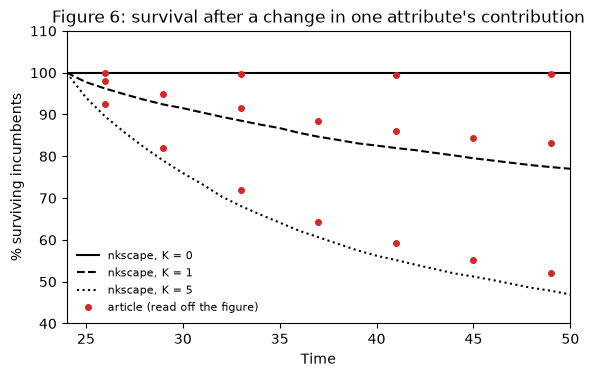

K = 0   period      26    33    41    49
        nkscape  100.0 100.0 100.0 100.0
        article  100.0  99.7  99.5  99.7
K = 1   period      26    29    33    37    41    45    49
        nkscape   96.2  92.4  88.5  84.7  82.0  79.5  77.4
        article   98.1  94.9  91.5  88.5  86.1  84.4  83.1
K = 5   period      26    29    33    37    41    45    49
        nkscape   89.5  78.9  68.1  60.6  55.2  51.2  47.8
        article   92.4  82.1  71.9  64.3  59.2  55.3  52.0
K = 0: 100.0 % alive in period 50, standard error 0.0
K = 1:  77.0 % alive in period 50, standard error 1.9
K = 5:  46.9 % alive in period 50, standard error 2.0


In [11]:
one_attribute = {k: incumbents_after_change(k, 1, climber) for k in (0, 1, 5)}
survival = {k: survival_share(histories) for k, histories in one_attribute.items()}

article_fig6 = {
    0: {26: 100.0, 33: 99.7, 41: 99.5, 49: 99.7},
    1: {26: 98.1, 29: 94.9, 33: 91.5, 37: 88.5, 41: 86.1, 45: 84.4, 49: 83.1},
    5: {26: 92.4, 29: 82.1, 33: 71.9, 37: 64.3, 41: 59.2, 45: 55.3, 49: 52.0},
}  # fmt: skip
plot_survival(
    survival,
    article_fig6,
    "Figure 6: survival after a change in one attribute's contribution",
    "fig6",
)

for k, histories in one_attribute.items():
    share = 100 * np.array([alive[:, -1].mean() for alive, _ in histories])
    error = share.std(ddof=1) / np.sqrt(RUNS)
    print(f"K = {k}: {share.mean():5.1f} % alive in period 50, standard error {error:.1f}")

assert (survival[0] == 100).all()
assert survival[0][-1] > survival[1][-1] > survival[5][-1]


## 4.1 Figure 7: reorientations and survival

Now the contributions of five attributes change in period 25. The figure relates the share of
surviving incumbents with at least one long jump to the same share among failed incumbents
(p. 945, fn. 11); values above 1 mean that survivors jumped more often. For $K = 1$ the ratio stays
close to 1, for $K = 5$ it rises toward 2: where attributes are tightly coupled, local repair
largely fails and survival goes with a successful reorientation (p. 945).

We count long jumps over each incumbent's whole life, as the article's footnote 11 suggests; the
original program counts only from period 24 onward, which yields ratios above 2 for both values of
$K$ and a graph that looks quite different from the article's.


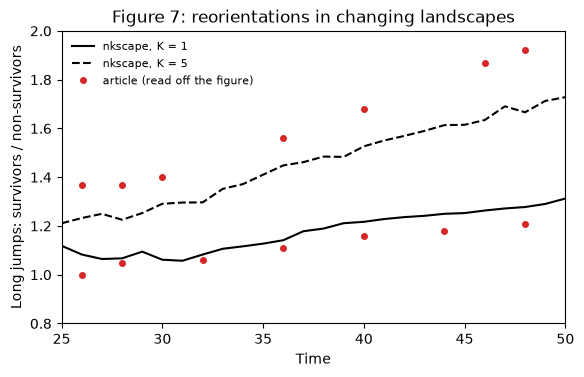

K = 1   period      26    28    32    36    40    44    48
        nkscape   1.08  1.07  1.08  1.14  1.22  1.25  1.28
        article   1.00  1.05  1.06  1.11  1.16  1.18  1.21
K = 5   period      26    28    30    36    40    46    48
        nkscape   1.23  1.23  1.29  1.45  1.53  1.63  1.67
        article   1.37  1.37  1.40  1.56  1.68  1.87  1.92


In [12]:
def jump_ratio(histories):
    survivors, others = [], []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        for alive, jumped in histories:
            survivors.append((jumped & alive).sum(axis=0) / alive.sum(axis=0))
            others.append((jumped & ~alive).sum(axis=0) / (~alive).sum(axis=0))
        return np.nanmean(survivors, axis=0) / np.nanmean(others, axis=0)


five_attributes = {k: incumbents_after_change(k, 5, climber) for k in (1, 5)}
ratio = {k: jump_ratio(histories) for k, histories in five_attributes.items()}

article_fig7 = {
    1: {26: 1.00, 28: 1.05, 32: 1.06, 36: 1.11, 40: 1.16, 44: 1.18, 48: 1.21},
    5: {26: 1.37, 28: 1.37, 30: 1.40, 36: 1.56, 40: 1.68, 46: 1.87, 48: 1.92},
}  # fmt: skip
_, ax = plt.subplots(figsize=(6.5, 3.8))
for k, style in {1: "-", 5: "--"}.items():
    ax.plot(range(25, 51), ratio[k][1:], color="black", linestyle=style, label=f"nkscape, K = {k}")
    ax.plot(list(article_fig7[k]), list(article_fig7[k].values()), **ARTICLE)
ax.plot([], [], label="article (read off the figure)", **ARTICLE)
ax.set(
    xlabel="Time",
    ylabel="Long jumps: survivors / non-survivors",
    xlim=(25, 50),
    ylim=(0.8, 2.0),
    title="Figure 7: reorientations in changing landscapes",
)
ax.legend(frameon=False, fontsize=8)
show("fig7")

for k, points in article_fig7.items():
    periods = sorted(points)
    print(f"K = {k}   period ", "".join(f"{t:6d}" for t in periods))
    print("        nkscape", "".join(f"{ratio[k][t - 24]:6.2f}" for t in periods))
    print("        article", "".join(f"{points[t]:6.2f}" for t in periods))

assert ratio[5][-1] > ratio[1][-1] > 1


## 5. Figure 8: number of local peaks

Levinthal's robustness section first shows that landscapes generated with the same $K$ are much
alike: the number of local peaks varies little around its mean (p. 946). For every $K$ from 0 to 8
we build 100 landscapes and count the peaks of each; a peak is a form with no fitter neighbor.
With $K = 0$ every landscape has exactly one peak; the mean rises to about 76 at $K = 8$.


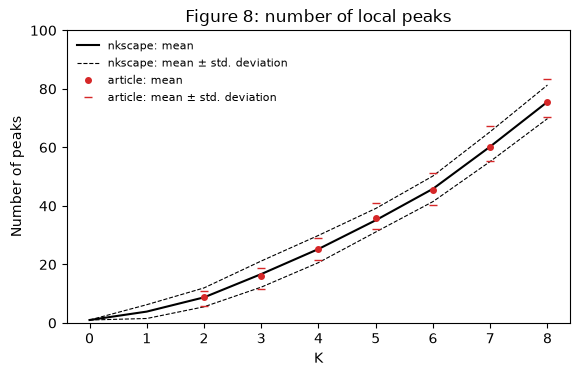

K                       0      1      2      3      4      5      6      7      8
nkscape mean          1.0    3.9    8.7   16.7   25.3   35.1   45.9   60.3   75.6
article mean          nan    nan    9.0   15.9   25.2   36.0   45.5   60.0   75.6
nkscape std. dev.     0.0    2.4    3.2    4.5    4.7    4.0    4.4    5.1    5.7


In [13]:
peaks = np.array(
    [
        [
            nk.Landscape.next_k(N, k, rng=stream).count_peaks()
            for stream in np.random.default_rng([SEED, k]).spawn(RUNS)
        ]
        for k in range(9)
    ]
)
mean, sd = peaks.mean(axis=1), peaks.std(axis=1, ddof=1)

# K = 0 and 1 cannot be read off the figure, the lines lie on the axis
article_mean = {2: 9.0, 3: 15.9, 4: 25.2, 5: 36.0, 6: 45.5, 7: 60.0, 8: 75.6}
article_low = {2: 5.7, 3: 11.7, 4: 21.5, 5: 32.2, 6: 40.3, 7: 55.3, 8: 70.4}
article_high = {2: 10.9, 3: 18.9, 4: 29.1, 5: 41.0, 6: 51.3, 7: 67.2, 8: 83.4}

_, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(range(9), mean, color="black", label="nkscape: mean")
ax.plot(
    range(9),
    mean - sd,
    color="black",
    linestyle="--",
    linewidth=0.8,
    label="nkscape: mean ± std. deviation",
)
ax.plot(range(9), mean + sd, color="black", linestyle="--", linewidth=0.8)
ax.plot(list(article_mean), list(article_mean.values()), label="article: mean", **ARTICLE)
ax.plot(
    list(article_low),
    list(article_low.values()),
    "_",
    color="tab:red",
    label="article: mean ± std. deviation",
)
ax.plot(list(article_high), list(article_high.values()), "_", color="tab:red")
ax.set(xlabel="K", ylabel="Number of peaks", ylim=(0, 100), title="Figure 8: number of local peaks")
ax.legend(frameon=False, fontsize=8)
show("fig8")

print("K                ", "".join(f"{k:7d}" for k in range(9)))
print("nkscape mean     ", "".join(f"{m:7.1f}" for m in mean))
print("article mean     ", "".join(f"{article_mean.get(k, float('nan')):7.1f}" for k in range(9)))
print("nkscape std. dev.", "".join(f"{s:7.1f}" for s in sd))

assert (peaks[0] == 1).all()
assert (np.diff(mean) > 0).all()


## 5.1 Noisy search

The robustness analysis lets organizations misjudge the forms they examine: the fitness they
perceive is the true fitness plus an error (pp. 946-947). To say how large an error is, Levinthal
reports the standard deviation of fitness as 0.09, hardly depending on $K$ (fn. 13). Fitness is the
mean of ten uniform numbers, so averaged over many landscapes its standard deviation is
$\sqrt{1/120} = 0.091$ for every $K$; within a single landscape it is smaller for small $K$,
because forms share table entries.


In [14]:
for k in (0, 1, 5, 8):
    streams = np.random.default_rng([SEED, k]).spawn(RUNS)
    cubes = np.array([nk.Landscape.next_k(N, k, rng=stream).fitness_cube() for stream in streams])
    together = cubes.std()
    within = np.sqrt(cubes.reshape(RUNS, -1).var(axis=1).mean())
    print(f"K = {k}: all landscapes together {together:.4f}, within one landscape {within:.4f}")
    assert abs(together - np.sqrt(1 / 120)) < 0.005
    assert abs(within - np.sqrt((1 - 2.0 ** -(k + 1)) / 120)) < 0.003

K = 0: all landscapes together 0.0941, within one landscape 0.0661
K = 1: all landscapes together 0.0911, within one landscape 0.0792
K = 5: all landscapes together 0.0909, within one landscape 0.0902
K = 8: all landscapes together 0.0912, within one landscape 0.0911



### Figure 9: survival with noisy search

The robustness analysis drops the assumption that an organization knows the exact fitness of the
forms it examines. It now perceives the fitness of a candidate form $\mathbf{d}'$ with an error,

$$\tilde V(\mathbf{d}') = V(\mathbf{d}') + u, \qquad u \sim U[-\Delta\varepsilon, \Delta\varepsilon],$$

where $\Delta$ is the number of attributes in which the candidate differs from the current form
and $\varepsilon$ is the noise level, set to 0.025 for high noise (p. 947). The error thus grows
with distance: a neighbor is judged quite accurately, a distant form much less so, and an
organization can mistake a worse form for a better one and adopt it. Figure 9 repeats the
experiment of Figure 6, one attribute's table redrawn at period 25, with this noise (pp. 947-948).
Levinthal's observations: $K = 0$ no longer survives at 100 %, $K = 0$ and $K = 1$ become
indistinguishable, and $K = 5$ still fares worst.


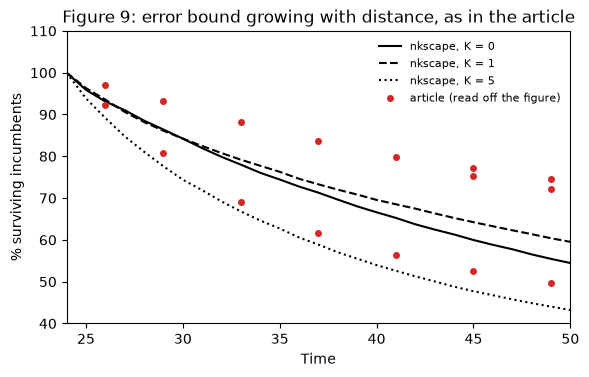

K = 0   period      26    29    33    37    41    45    49
        nkscape   93.1  86.4  78.0  71.3  65.3  60.0  55.5
        article   97.1  93.2  88.2  83.7  79.8  75.4  72.2
K = 1   period      45    49
        nkscape   64.2  60.4
        article   77.1  74.5
K = 5   period      26    29    33    37    41    45    49
        nkscape   89.2  77.6  66.8  58.9  52.6  47.7  44.0
        article   92.3  80.7  69.1  61.7  56.4  52.5  49.6


In [15]:
class NoisyClimber(nk.Agent):
    def __init__(self, epsilon, grows_with_distance):
        self.epsilon = epsilon
        self.grows_with_distance = grows_with_distance

    def step(self, config, landscape, rng, population):
        current = landscape.fitness(config)
        perceived = landscape.neighbour_fitness(config) + rng.uniform(
            -self.epsilon, self.epsilon, N
        )
        better = np.flatnonzero(perceived > current)
        next_config = config
        if better.size > 0:
            next_config = config.copy()
            next_config[better[0]] ^= 1

        jump = landscape.random_configuration(rng)
        distance = (jump != next_config).sum() if self.grows_with_distance else 1
        bound = self.epsilon * distance
        if landscape.fitness(jump) + rng.uniform(-bound, bound) > landscape.fitness(next_config):
            return jump
        return next_config


article_fig9 = {
    0: {26: 97.1, 29: 93.2, 33: 88.2, 37: 83.7, 41: 79.8, 45: 75.4, 49: 72.2},
    1: {45: 77.1, 49: 74.5},
    5: {26: 92.3, 29: 80.7, 33: 69.1, 37: 61.7, 41: 56.4, 45: 52.5, 49: 49.6},
}  # fmt: skip


def noisy_survival(grows_with_distance):
    make_agent = partial(NoisyClimber, 0.025, grows_with_distance)
    return {k: survival_share(incumbents_after_change(k, 1, make_agent)) for k in (0, 1, 5)}


text_rule = noisy_survival(grows_with_distance=True)
plot_survival(
    text_rule,
    article_fig9,
    "Figure 9: error bound growing with distance, as in the article",
    "fig9_article_rule",
)


The curves lie well below the article's: with an error bound that grows with distance, long jumps
are misjudged by up to 0.125 and mistaken jumps are frequent and costly. We therefore checked the
original program. It computes the bound as `alpha + Lmax*(d-1)/d` and runs with `Lmax = 0`, so the
same bound $\varepsilon$ applies to every candidate regardless of its distance.

### Figure 9, with the noise rule of the original program

With the program's rule, the same bound $\varepsilon = 0.025$ for neighbors and long jumps, the
figure is reproduced.


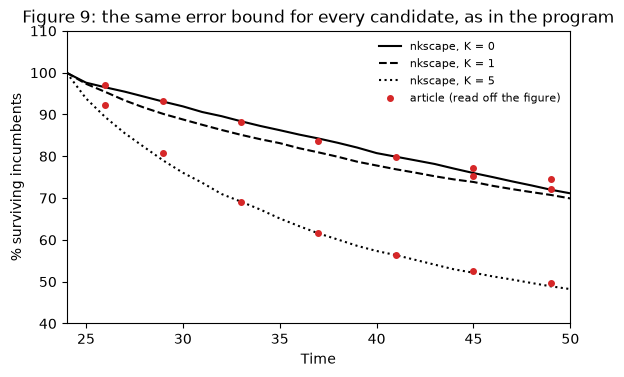

K = 0   period      26    29    33    37    41    45    49
        nkscape   96.5  93.1  88.4  84.3  79.9  76.0  72.0
        article   97.1  93.2  88.2  83.7  79.8  75.4  72.2
K = 1   period      45    49
        nkscape   73.9  70.7
        article   77.1  74.5
K = 5   period      26    29    33    37    41    45    49
        nkscape   89.4  79.0  69.1  61.6  56.4  52.1  48.9
        article   92.3  80.7  69.1  61.7  56.4  52.5  49.6


In [16]:
program_rule = noisy_survival(grows_with_distance=False)
plot_survival(
    program_rule,
    article_fig9,
    "Figure 9: the same error bound for every candidate, as in the program",
    "fig9_program_rule",
)

for noisy in (text_rule, program_rule):
    assert noisy[0][-1] < 100
    assert noisy[5][-1] < min(noisy[0][-1], noisy[1][-1])
    assert abs(noisy[0][-1] - noisy[1][-1]) < 10


## Appendix: the order in which neighbors are examined

The article says an organization adopts the first superior form it discovers but not in which
order it looks. The original program tries $d_1$, then $d_2$, and so on. Looking in random order
instead ends in almost the same place but gets there more slowly: with a fixed order every
organization repairs its lowest-numbered attributes first, so organizations become alike sooner.
Only the fixed order reproduces Figure 1.


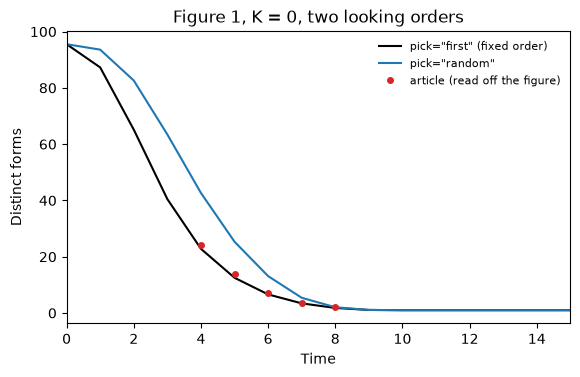

In [17]:
random_order = forms_over_time(simulate(0, lambda: nk.agents.HillClimber("random")))

_, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(local_forms[0].mean(axis=0), color="black", label='pick="first" (fixed order)')
ax.plot(random_order.mean(axis=0), color="tab:blue", label='pick="random"')
ax.plot(
    list(article_fig1[0]),
    list(article_fig1[0].values()),
    label="article (read off the figure)",
    **ARTICLE,
)
ax.set(
    xlabel="Time",
    ylabel="Distinct forms",
    xlim=(0, 15),
    title="Figure 1, K = 0, two looking orders",
)
ax.legend(frameon=False, fontsize=8)
show("appendix_search_order")